# NEAREST NEIGHBOUR METHOD (SS 0.1)

<img src="assets\nearestNei.png" alt="Proof image" width="300" />

## 1. Simple Upscalilng 

In [1]:
"""
What even is upscaling and nearest neighbour upscaling?
"""


import math
import numpy as np

from PIL import Image

arr = np.array([[0,64],[128,255]],dtype=np.uint8)


# [
#     0   64
#     128 255
# ]

#inlarge by nearest neighbour (change to 4x4)

horizontal = np.repeat(arr,2,axis=1)
# print(horizontal)

vertical = np.repeat(horizontal,2,axis=0)
# print(vertical)


#Create the image from the matrix
# Image.fromarray(arr).save("original.png")
# Image.fromarray(vertical).save("upscaled.png")


print(arr.shape)
print(vertical.shape)

(2, 2)
(4, 4)


## 2. Linear Interpolation (LERP)

Estimate the value of a point between 2 endpoints, Using 

v(t) = (1-t)a + t(b); where t -> point wehre we want to find, a -> pont 1 , b -> point 2

Proof:

<img src="assets\lerp.jpeg" alt="Proof image" width="250" />


In [2]:
def lerp(a : float ,b : float,t : float):
    if 0 <= t <= 1:
        return a*(1-t) + t*(b)
    raise ValueError("t must be between 0 and 1")

lerp(0,64,0.5)


32.0

In [3]:
print(lerp(0, 64, 0.25))
print(lerp(0, 64, 0.75))

16.0
48.0


## 3. Bi-Linear Interpolation

Doing interpolation Horizontally and then Vertically


For :
```
          left   right
top         0      64
bottom    128     255
```

To estimate the value at its center:
1. Interpolate halfway across the top row.
2. Interpolate halfway across the bottom row.
3. Interpolate halfway between those two results.

In [4]:
#example of 2x2 matrix
t = 0.5
l1 = lerp(arr[0][0],arr[0][1],t)
l2 = lerp(arr[1][0],arr[1][1],t)
l3 = lerp(l1,l2,t)

l3

np.float64(111.75)

In [5]:
# Bi-Lerp

def biLerp(a,b,c,d,tx,ty):
    l1 = lerp(a,b,tx)
    l2 = lerp(c,d,tx)
    l3 = lerp(l1,l2,ty)

    return l3

In [6]:
biLerp(0, 64, 128, 255, 0.5, 0.5)

111.75

In [7]:
print(biLerp(0, 64, 128, 255, 0, 0))
print(biLerp(0, 64, 128, 255, 1, 0))
print(biLerp(0, 64, 128, 255, 0, 1))
print(biLerp(0, 64, 128, 255, 1, 1))

0
64
128
255



\begin{bmatrix}
0 & 64 \\
128 & 255
\end{bmatrix}


↓

```text
          0                    1

0         0      (0.5, 0)     64
          |                    |
          |                    |
       (0, 0.5)   111.75   (1, 0.5)
          |                    |
          |                    |
1        128     (0.5, 1)     255


We BiLErp on the coordinates

In [8]:
# loop over the 3x3 array and calculate the pixel values using bilerp and coordinates of t
res = np.zeros((3,3),dtype=float)
pos = [0,0.5,1]

for row,ty in enumerate(pos):
    for col,tx in enumerate(pos):
        res[row][col] = biLerp(float(arr[0,0]), float(arr[0,1]),
                               float(arr[1,0]),float(arr[1,1]),
                               tx,ty)

# res
image_array = np.clip(np.rint(res), 0, 255).astype(np.uint8)

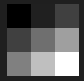

In [9]:
# doing it over a 4x4 array 
res4 = np.zeros((4,4),dtype=float)
pos = [0,0.25,0.75,1]

for r,ty in enumerate(pos):
    for c,tx in enumerate(pos):
        res4[r][c] = biLerp(
            float(arr[0,0]), float(arr[0,1]),
            float(arr[1,0]),float(arr[1,1]),
            tx,ty
        )

# res4
image_array = np.clip(np.rint(res), 0, 255).astype(np.uint8)

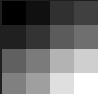

Having fun on a 1kx1k

In [10]:
resMax = np.zeros((1000,1000),dtype=float)
pos = np.linspace(0, 1, 1000)

for r,ty in enumerate(pos):
    for c,tx in enumerate(pos):
        resMax[r][c] = biLerp(
            float(arr[0,0]), float(arr[0,1]),
            float(arr[1,0]),float(arr[1,1]),
            tx,ty
        )

# resMax
image_array = np.clip(np.rint(resMax), 0, 255).astype(np.uint8)

# Image.fromarray(image_array).save("dshdsf83dsfs.png")


<img src="assets\biLerpMaxx.png" alt="Proof image" width="250" />

In [11]:
def findNeigh(x,y,height,width):
    x = max(0, min(x, width - 1))
    y = max(0, min(y, height - 1))
    x0 = int(np.floor(x))
    y0 = int(np.floor(y))

    x1 = min(x0 + 1, width - 1)
    y1 = min(y0 + 1, height - 1)

    tx = x - x0
    ty = y - y0

    return x0, y0, x1, y1, tx, ty


In [12]:
image = np.array([
    [  0,  40,  80, 120],
    [ 60, 100, 140, 180],
    [120, 160, 200, 240]
], dtype=float)

height = len(image)
width = len(image[0])

x = 1.25 ; y = 0.5
x0,y0,x1,y1,tx,ty = findNeigh(x,y,height,width)

a = image[y0, x0]
b = image[y0, x1]
c = image[y1, x0]
d = image[y1, x1]

biLerp(a,b,c,d,tx,ty)



np.float64(80.0)

We can now find the 4 points around which to bilerp, now we know how to find the inputs where we have to do the bilerp.

x = (col + 0.5) / scale - 0.5
y = (row + 0.5) / scale - 0.5

This tell us the position (x,y) where we should do bilerp on, 
We then find all the neighbours (a,b,c,d,tx,ty)

and we finaly get our answer to that point

In [18]:
def upscale_bilinear(image,scale):
    height,width = image.shape
    output = np.zeros((height*scale, width*scale),dtype=float)

    # go over each cell in the output
    for row in range(output.shape[0]):
        for col in range(output.shape[1]):
            #1 find the input point (x,y) 
            # these are the new pixel centers after expanding
            x = (col + 0.5) / scale - 0.5
            y = (row + 0.5) / scale - 0.5


            #2 find its neighbours (find the neighbours it should take values from)
            x0,y0,x1,y1,tx,ty = findNeigh(x,y,height,width)

            a = image[y0, x0]
            b = image[y0, x1]
            c = image[y1, x0]
            d = image[y1, x1]
            
            #3 bilerp
            val = biLerp(a,b,c,d,tx,ty)

            #4 store in output the res

            output[row][col] = val
    # print(output)
    return output


## This is optimized as hell (production style almost)

In [33]:
def upscale_bilinear_vectorized(image,scale):
    height,width = image.shape
    outHeight,outWidth = height*scale,width*scale

    rows = np.arange(outHeight,dtype=np.float32 )
    cols = np.arange(outWidth,dtype=np.float32 )

    x = (cols + 0.5) / scale - 0.5
    y = (rows + 0.5) / scale - 0.5

    X,Y = np.meshgrid(x,y)  # creates a vectorized array all at once, no for loops (does the calculations at once parrallely)

    # 2. Compute floor indices and fractional weights vectorially
    x0 = np.floor(X).astype(np.int32)
    y0 = np.floor(Y).astype(np.int32)

    # Safely clamp upper and lower bounds to prevent index errors
    x1 = np.clip(x0+1,0,width-1)
    y1 = np.clip(y0+1,0,height-1)
    x0 = np.clip(x0,0,width-1)
    y0 = np.clip(y0,0,height-1)

    tx = X - x0
    ty = Y - y0

    # 3. Vectorized neighbor gathering using advanced indexing
    Ia = image[y0, x0]
    Ib = image[y0, x1]
    Ic = image[y1, x0]
    Id = image[y1, x1]
    
    # 4. Vectorized Bilinear Interpolation formula (executed across all pixels at once)
    top = Ia * (1.0 - tx) + Ib * tx
    bottom = Ic * (1.0 - tx) + Id * tx
    output = top * (1.0 - ty) + bottom * ty

    return output
    

In [32]:
# result = upscale_bilinear_vectorized(image,2)
result = upscale_bilinear(image,2)
print(result)
print(result.shape)

[[  0.  10.  30.  50.  70.  90. 110. 120.]
 [ 15.  25.  45.  65.  85. 105. 125. 135.]
 [ 45.  55.  75.  95. 115. 135. 155. 165.]
 [ 75.  85. 105. 125. 145. 165. 185. 195.]
 [105. 115. 135. 155. 175. 195. 215. 225.]
 [120. 130. 150. 170. 190. 210. 230. 240.]]
(6, 8)


In [ ]:
# test to see if 1x scaling does not change stuff

image = np.array([
    [  0,  40,  80, 120],
    [ 60, 100, 140, 180],
    [120, 160, 200, 240]
], dtype=float)

unchanged = upscale_bilinear_vectorized(image,1)
print(np.allclose(unchanged, image)) 

True


Take your image and change in b&w, and perfrom bilerp on it.

In [ ]:

photo = Image.open("ginue-pigs/monkey.jpg").convert("L")
image = np.asarray(photo,dtype=float)

print(image.shape)

In [ ]:
res = upscale_bilinear_vectorized(image,2)
image_array = np.clip(np.rint(res), 0, 255).astype(np.uint8)
res.shape
# Image.fromarray(image_array).save("doublt.png")